# 03. Linear regression for next-day visits

The models predict daily visits at J+1, with observed volumes updated each day. All main comparisons use 1 January through 31 December 2022 as a development evaluation period and train on earlier dates. The calendar variants are also compared with expanding-window validation before 2022. The year 2023 remains reserved for the final test.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import TimeSeriesSplit
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score


project_dir = Path.cwd().parent
path = project_dir / "data" / "processed" / "df_cleaned.parquet"

try:
    df = pd.read_parquet(path, filters=[("date", "<", pd.Timestamp("2023-01-01"))])
    # If you've run Notebook 1 all the way through, you shouldn't have any problems with this try
except (FileNotFoundError, ImportError):  # Otherwise, we can reapply the transformations here
    file = project_dir / "data" / "raw" / "emergency-visits-2017-2023.csv"
    df_raw = pd.read_csv(file, sep=";").query("date < '2023-01-01'")
    df_fr = df_raw[df_raw["dep"] == "69"].copy()
    df_fr["date"] = pd.to_datetime(df_fr["date"])
    df_fr = df_fr.sort_values("date")
    df_fr = df_fr.set_index("date")
    df = df_fr.rename(columns={"nb_passages": "visits"})
    df = df[["visits"]]
df1 = df.sort_index().copy()
validation_start = pd.Timestamp("2022-01-01")

In [2]:

df = df1.copy()
df["visits_lag1"] = df["visits"].shift(periods=1)
df = df.iloc[7:].copy() # Use the same dates as models that require seven days of history.
X = df[["visits_lag1"]]
y = df["visits"]
df

,visits,visits_lag1
date,,
2017-01-08,1603.4,1730.0
2017-01-09,1727.5,1603.4
2017-01-10,1617.2,1727.5
2017-01-11,1567.1,1617.2
2017-01-12,1336.4,1567.1
...,...,...
2022-12-27,1708.2,2006.7
2022-12-28,1693.6,1708.2
2022-12-29,1681.9,1693.6


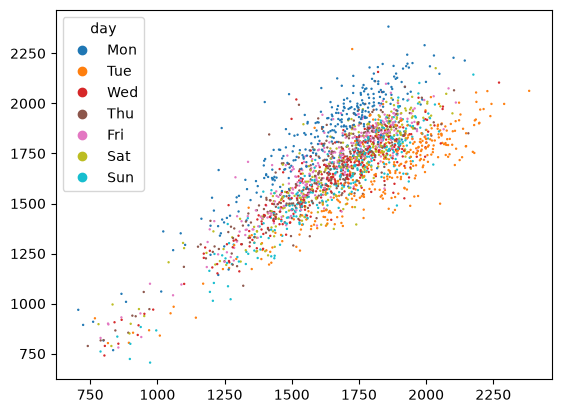

In [3]:
scatter = plt.scatter(X, y, s=0.5, c=X.index.day_of_week, cmap="tab10")

handles, _ = scatter.legend_elements()
days = ["Mon", "Tue", "Wed", "Thu", "Fri", "Sat", "Sun"]
plt.legend(handles, days, title="day")

In [4]:
split = df.index.searchsorted(validation_start)
X_train, X_test = X.iloc[:split],X.iloc[split:]
y_train, y_test = y.iloc[:split],y.iloc[split:]
model = LinearRegression()
model.fit(X_train,y_train)
print(model.score(X_train,y_train))
y_pred = model.predict(X_test)
y_dumb = X_test["visits_lag1"]

0.69452719786038


In [5]:
def evaluate(name, y_true, y_hat):
    print(f"{name:10s} MAE={mean_absolute_error(y_true, y_hat):.2f}  "
          f"RMSE={np.sqrt(mean_squared_error(y_true, y_hat)):.2f}  "
          f"R²={r2_score(y_true, y_hat):.3f}")

evaluate("Previous day", y_test, y_dumb)
evaluate("Previous week", y_test, df1["visits"].shift(7).loc[y_test.index])
evaluate("LinReg", y_test, y_pred)

print(f"coef={model.coef_[0]:.3f}  intercept={model.intercept_:.2f}")

Previous day MAE=102.90  RMSE=139.18  R²=0.160
Previous week MAE=86.30  RMSE=107.42  R²=0.500
LinReg     MAE=97.20  RMSE=129.88  R²=0.269
coef=0.834  intercept=279.86


In [6]:
df = df1.copy() # we removed 1 January in the previous df, so we bring it back
df["visits_lag1"] = df["visits"].shift(periods=1)
df["visits_lag7"] = df["visits"].shift(periods=7)
df = df.dropna(subset=["visits_lag7"]) #remove the first week of 2017 value since we don't know about the last week of 2016
X = df[["visits_lag1","visits_lag7"]]
y = df["visits"]

In [7]:
split = df.index.searchsorted(validation_start)
X_train, X_test = X.iloc[:split],X.iloc[split:]
y_train, y_test = y.iloc[:split],y.iloc[split:]
model = LinearRegression()
model.fit(X_train,y_train)
print(model.score(X_train,y_train))
y_pred = model.predict(X_test)
y_dumb = X_test["visits_lag7"]

0.7996854177458976


In [8]:
evaluate("Previous day", y_test, X_test["visits_lag1"])
evaluate("Previous week", y_test, y_dumb)
evaluate("Linear regression", y_test, y_pred)
print(pd.Series(model.coef_, index=X.columns).round(3))
print("Intercept:", round(model.intercept_, 2))

Previous day MAE=102.90  RMSE=139.18  R²=0.160
Previous week MAE=86.30  RMSE=107.42  R²=0.500
Linear regression MAE=75.97  RMSE=95.15  R²=0.608
visits_lag1    0.444
visits_lag7    0.507
dtype: float64
Intercept: 82.09


In [9]:
dow = pd.get_dummies(df.index.day_of_week, prefix="dow", drop_first=True).astype(int)
dow.index = df.index
X_base = df[["visits_lag1", "visits_lag7"]]
X_dow  = pd.concat([X_base, dow], axis=1)

split = df.index.searchsorted(validation_start)
y_train, y_test = y.iloc[:split], y.iloc[split:]

evaluate("Today=Last Week", y_test, X_base["visits_lag7"].iloc[split:])
models = {}
for name, X_ in [("LinReg lag1+lag7", X_base), ("LinReg + one-hot day", X_dow)]:
    X_train, X_test = X_.iloc[:split], X_.iloc[split:]
    m = LinearRegression().fit(X_train, y_train)
    models[name] = (m, X_.columns)
    evaluate(name, y_test, m.predict(X_test))

# Coefficients of the one-hot model
m, cols = models["LinReg + one-hot day"]
print(pd.Series(m.coef_, index=cols).round(2))
print("intercept:", round(m.intercept_, 2))

Today=Last Week MAE=86.30  RMSE=107.42  R²=0.500
LinReg lag1+lag7 MAE=75.97  RMSE=95.15  R²=0.608
LinReg + one-hot day MAE=56.47  RMSE=73.61  R²=0.765
visits_lag1      0.71
visits_lag7      0.24
dow_1         -276.98
dow_2         -168.54
dow_3         -127.15
dow_4         -122.80
dow_5         -146.29
dow_6         -193.52
dtype: float64
intercept: 232.25


In [10]:
import holidays

# French public holidays for the years in df
fr_holidays = holidays.France(years=range(df.index.year.min() - 1, df.index.year.max() + 2))
holiday_dates = pd.to_datetime(list(fr_holidays.keys()))

one_day    = pd.Timedelta(days=1)
is_holiday = df.index.isin(holiday_dates)
day_before = (df.index + one_day).isin(holiday_dates)   # tomorrow is a holiday
day_after  = (df.index - one_day).isin(holiday_dates)   # yesterday was a holiday
bridge_day = (
    ((df.index.day_of_week == 4) & (df.index - one_day).isin(holiday_dates)) |  # Friday after a Thursday holiday
    ((df.index.day_of_week == 0) & (df.index + one_day).isin(holiday_dates))    # Monday before a Tuesday holiday
)

hol_feats = pd.DataFrame({
    "is_holiday": is_holiday,
    "day_before_holiday": day_before,
    "day_after_holiday": day_after,
    "bridge_day": bridge_day,
}, index=df.index).astype(int)

X_hol = pd.concat([X_dow, hol_feats], axis=1)

# Comparison (same split, same evaluate function)
for name, X_ in [("LinReg + one-hot day", X_dow), ("LinReg + one-hot + holidays", X_hol)]:
    X_train, X_test = X_.iloc[:split], X_.iloc[split:]
    m = LinearRegression().fit(X_train, y_train)
    evaluate(name, y_test, m.predict(X_test))

print(pd.Series(m.coef_, index=X_hol.columns).round(2))

# Largest remaining residuals: are they "special" days?
res = (y_test - m.predict(X_hol.iloc[split:]))
print(res.abs().sort_values(ascending=False).head(10))

LinReg + one-hot day MAE=56.47  RMSE=73.61  R²=0.765
LinReg + one-hot + holidays MAE=53.48  RMSE=69.11  R²=0.793
visits_lag1             0.75
visits_lag7             0.20
dow_1                -302.70
dow_2                -179.97
dow_3                -137.82
dow_4                -135.31
dow_5                -157.60
dow_6                -207.78
is_holiday            -87.87
day_before_holiday     -0.21
day_after_holiday     183.90
bridge_day             38.38
dtype: float64
date
2022-12-31    288.808496
2022-12-24    239.194976
2022-11-03    221.408364
2022-05-28    200.244266
2022-07-16    188.712644
2022-09-04    183.942823
2022-04-20    177.318639
2022-06-19    176.540450
2022-05-27    160.195797
2022-05-06    157.009692
Name: visits, dtype: float64


In [11]:
# Compare additions against the same holiday model.
month_day = df.index.strftime("%m-%d")
eve = month_day.isin(["12-24", "12-31"]).astype(int)

day_of_year = df.index.day_of_year
season = pd.DataFrame({
    f"{function}{k}": getattr(np, function)(2 * np.pi * k * day_of_year / 365.25)
    for k in (1, 2) for function in ("sin", "cos")
}, index=df.index)

X_eve = X_hol.assign(christmas_eve=eve)
X_season = pd.concat([X_hol, season], axis=1)
X_both = pd.concat([X_eve, season], axis=1)
calendar_variants = {
    "Holidays": X_hol,
    "Holidays + eves": X_eve,
    "Holidays + seasonality": X_season,
    "Holidays + both": X_both,
}

for name, features in calendar_variants.items():
    model = LinearRegression().fit(features.iloc[:split], y_train)
    evaluate(name, y_test, model.predict(features.iloc[split:]))

Holidays   MAE=53.48  RMSE=69.11  R²=0.793
Holidays + eves MAE=52.96  RMSE=67.46  R²=0.803
Holidays + seasonality MAE=53.75  RMSE=69.23  R²=0.792
Holidays + both MAE=53.20  RMSE=67.61  R²=0.802


In [12]:
# Expanding-window validation before the 2022 development comparison.
tscv = TimeSeriesSplit(n_splits=5)
development_target = y.iloc[:split]
folds = list(tscv.split(development_target))
print("Validation periods:", [
    (str(development_target.index[te[0]].date()), str(development_target.index[te[-1]].date()))
    for _, te in folds
])

for name, features in calendar_variants.items():
    development_features = features.iloc[:split]
    maes = []
    for tr, te in folds:
        model = LinearRegression().fit(development_features.iloc[tr], development_target.iloc[tr])
        predictions = model.predict(development_features.iloc[te])
        maes.append(mean_absolute_error(development_target.iloc[te], predictions))
    print(f"{name:24s} {np.round(maes, 1)}  mean={np.mean(maes):.2f}")

Validation periods: [('2017-11-08', '2018-09-06'), ('2018-09-07', '2019-07-06'), ('2019-07-07', '2020-05-04'), ('2020-05-05', '2021-03-03'), ('2021-03-04', '2021-12-31')]
Holidays                 [73.8 72.3 91.5 59.6 58.2]  mean=71.07
Holidays + eves          [73.8 70.8 89.6 58.1 57.3]  mean=69.91
Holidays + seasonality   [74.9 73.6 94.2 60.8 58.4]  mean=72.39
Holidays + both          [74.9 72.  91.6 59.7 57.7]  mean=71.20


## Conclusion

For the next comparison of J+1 regression models, use the feature set in `X_eve`:

- **Recent visits** recorded one day and seven days before the target date (`visits_lag1` and `visits_lag7`).
- **Day of the week** of the target date, encoded as indicator variables.
- **Public holidays and nearby days**, using indicators for the holiday itself, the preceding day, the following day and bridge days.
- **Christmas Eve and New Year's Eve**, represented by a shared indicator for December 24 and 31.

On the same 365 days of 2022, adding the day of the week to the two visit lags reduced MAE from 75.97 to 56.47 visits per day. The public holiday indicators reduced it further to 53.48. This comparison tested the holiday indicators together, so it does not measure their individual contributions. Adding the shared eve indicator brought MAE down to 52.96 in 2022 and from 71.07 to 69.91 on average across the five earlier validation periods.

Leave the two tested annual harmonics out of this feature set. They increased MAE with and without the eve indicator in both comparisons.

Use this linear regression as the reference when comparing other regression models on the same features and chronological splits. The year 2023 remains reserved for the final test.

In [100]:
X_eve.columns

Index(['visits_lag1', 'visits_lag7', 'dow_1', 'dow_2', 'dow_3', 'dow_4',
       'dow_5', 'dow_6', 'is_holiday', 'day_before_holiday', 'day_after_holiday',
       'bridge_day', 'christmas_eve'],
      dtype='str')

In [97]:
from sklearn.linear_model import LinearRegression

for feats in [["visits_lag1"], ["visits_lag7"], ["visits_lag1", "visits_lag7"]]:
    m = LinearRegression().fit(X_train[feats], y_train)
    print(f"{feats} | train={m.score(X_train[feats], y_train):.4f} | "
          f"test={m.score(X_test[feats], y_test):.4f}")

['visits_lag1'] | train=0.6945 | test=0.2687
['visits_lag7'] | train=0.7190 | test=0.5484
['visits_lag1', 'visits_lag7'] | train=0.7997 | test=0.6075


In [103]:
import numpy as np
from sklearn.linear_model import RidgeCV
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import TimeSeriesSplit

tscv = TimeSeriesSplit(n_splits=5)
alphas = np.logspace(-4, 6, 200)

ridge = make_pipeline(
    StandardScaler(),
    RidgeCV(alphas=alphas, cv=tscv)
)
ridge.fit(X_train, y_train)
print(f"Ridge | train={ridge.score(X_train, y_train):.4f} | "
      f"test={ridge.score(X_test, y_test):.4f}")
print(f"Alpha optimal : {ridge[-1].alpha_:.2e}")

Ridge | train=0.8812 | test=0.8029
Alpha optimal : 3.74e+00
